# 01 · Data: SemEval-2020 SentiMix (Hinglish)

**Project:** Robust, Trustworthy and Efficient Hinglish Sentiment Analysis (CS-685, IIT Mandi)

This notebook is step 1 of the plan (*Data*): get the official SentiMix Hinglish data, clean it, understand it, and save a fixed **14K / 3K / 3K** split that every later notebook reads.

| Step | What we do |
|---|---|
| 1 | Download from Zenodo (record 3974927) |
| 2 | Parse the CoNLL format (one word per line + language tag) |
| 3 | Fix broken emoji encoding, re-join URLs / @mentions / #hashtags |
| 4 | Explore: labels, length, language mix, spelling variation |
| 5 | Save `data/processed/{train,val,test}.jsonl` |

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RAW_DIR = ROOT / "data/raw/Semeval_2020_task9_data/Hinglish"
PROC_DIR = ROOT / "data/processed"
FIG_DIR = ROOT / "results/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"negative": "#C0504D", "neutral": "#8A8FA3", "positive": "#377D72"}

## 1. Download (skipped if already present)

In [2]:
import urllib.request, zipfile
zip_path = ROOT / "data/raw/Semeval_2020_task9_data.zip"
if not RAW_DIR.exists():
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    url = "https://zenodo.org/api/records/3974927/files/Semeval_2020_task9_data.zip/content"
    urllib.request.urlretrieve(url, zip_path)
    zipfile.ZipFile(zip_path).extractall(zip_path.parent)
sorted(p.name for p in RAW_DIR.iterdir())

['Hinglish_dev_3k_split_conll.txt',
 'Hinglish_test_labels.txt',
 'Hinglish_test_unalbelled_conll_updated.txt',
 'Hinglish_train_14k_split_conll.txt']

## 2. Raw format

Each tweet starts with a `meta` line (`id`, `label`); then one token per line with its **language tag**: `Hin` (Hindi in Roman letters), `Eng`, `O` (punctuation, mentions, URLs), `EMT` (emoji). The test labels come in a separate CSV.

In [3]:
print("".join(open(RAW_DIR / "Hinglish_train_14k_split_conll.txt", encoding="utf-8").readlines()[31:52]))

Haan	Hin
yaar	Hin
neha	Hin
😔😔	O
kab	Hin
karega	Hin
woh	Hin
post	Hin
😭	EMT
Usne	Hin
na	Hin
sach	Hin
mein	Hin
photoshoot	Eng
karna	Hin
chahiye	Hin
phir	Hin
woh	Hin
post	Hin
karega	Hin
…	O



## 3. Parse + clean

In [4]:
from hinglish.data import load_raw_splits, LABELS

splits = load_raw_splits(RAW_DIR)
for name, df in splits.items():
    print(f"{name:5s} {len(df):6,d} tweets | unique ids: {df.uid.nunique():,} | missing labels: {df.label.isna().sum()}")

train 14,000 tweets | unique ids: 14,000 | missing labels: 0
val    3,000 tweets | unique ids: 3,000 | missing labels: 0
test   3,000 tweets | unique ids: 3,000 | missing labels: 0


The original tokeniser split URLs and mentions into pieces. `text` is the cleaned version we feed to models; `text_raw` keeps the original tokens joined by spaces.

In [5]:
pd.set_option("display.max_colwidth", 140)
splits["train"][["text_raw", "text", "label"]].sample(6, random_state=1)

,text_raw,text,label
12339,@_ Mansoor _ Ali Msg pay he to tera aur teri family ka pait palta hai msg na hoty to tere jesy chutiye ko kon ghaas dalta,@user Msg pay he to tera aur teri family ka pait palta hai msg na hoty to tere jesy chutiye ko kon ghaas dalta,negative
10123,@ DrMuradPTI bundel of thanks Sir 👏❤❤ Allah Pak apko salam rakhein * Ameen *,@user bundel of thanks Sir 👏❤❤ Allah Pak apko salam rakhein * Ameen *,positive
13977,@ Selvan33804547 @ Alpha _ crusader _ @ TVijayarahavan Kyu be madarchod ?? English teri ma chudane bolta je bhadve ... teri … https // t...,@user @user @user Kyu be madarchod ?? English teri ma chudane bolta je bhadve ... teri http,negative
1520,@ RoflIndian3 @ sardanarohit Tum chamche nahi badle ab Janta ne muh me peshaab mar diya ab kya tatti chahte ho Co … https // t co / X57U...,@user @user Tum chamche nahi badle ab Janta ne muh me peshaab mar diya ab kya tatti chahte ho Co http co / X57U9TFfBt,negative
5815,@ Ravikan03251268 @ narendramodi Aaj wo log Kahan Hain Jo bolte the gayo ki sambhal karo unko khula chodoge to Musli … https // t . co /...,@user @user Aaj wo log Kahan Hain Jo bolte the gayo ki sambhal karo unko khula chodoge to Musli http,negative
5860,@ ppbajpai Tu to 50 saal main bi bhadwagiri nahi chodd paya ... presstitute we have elected Govt not ur fathers ...,@user Tu to 50 saal main bi bhadwagiri nahi chodd paya ... presstitute we have elected Govt not ur fathers ...,negative


Some emoji in the raw files are mojibake (UTF-8 read as Latin-1, e.g. `ðŸ˜…`). `ftfy` repairs them during parsing:

In [6]:
import ftfy
for broken in ["ðŸ˜…", "ðŸ˜‚", "à¤¹"]:
    print(f"{broken!r:12} -> {ftfy.fix_text(broken)}")

'ðŸ˜…'       -> 😅
'ðŸ˜‚'       -> 😂
'à¤¹'        -> ह


## 4. Explore
### 4.1 Labels — balanced enough, neutral is the largest class

,train,val,test,train %,val %,test %
label,,,,,,
negative,4102,890,900,29.3,29.7,30.0
neutral,5264,1128,1100,37.6,37.6,36.7
positive,4634,982,1000,33.1,32.7,33.3


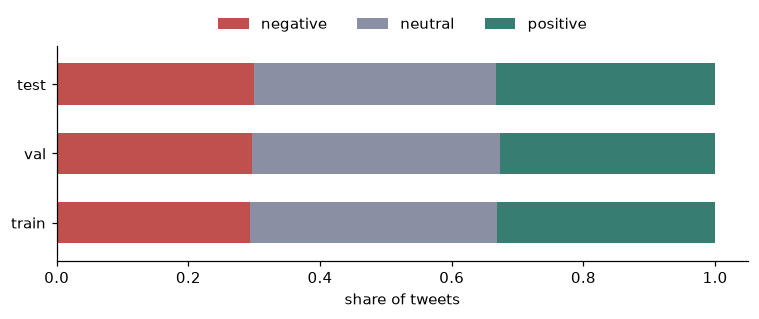

In [7]:
counts = pd.DataFrame({n: d.label.value_counts() for n, d in splits.items()}).loc[LABELS]
display(counts.assign(**{f"{n} %": (counts[n] / counts[n].sum() * 100).round(1) for n in counts}))

fig, ax = plt.subplots(figsize=(7, 3))
(counts / counts.sum()).T.plot.barh(stacked=True, ax=ax, color=[COLORS[l] for l in LABELS], width=0.6)
ax.set_xlabel("share of tweets"); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "01_label_distribution.png"); plt.show()

### 4.2 Tweet length

count    14000.0
mean        26.1
std          6.4
min          1.0
25%         22.0
50%         28.0
75%         31.0
max         56.0


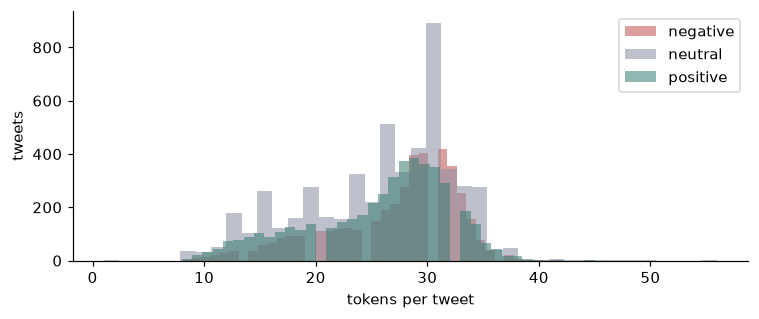

In [8]:
train = splits["train"]
print(train.n_tokens.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 3))
for l in LABELS:
    ax.hist(train.loc[train.label == l, "n_tokens"], bins=40, alpha=0.55, label=l, color=COLORS[l])
ax.set_xlabel("tokens per tweet"); ax.set_ylabel("tweets"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "01_length.png"); plt.show()

### 4.3 How mixed is the language?

Token-level tags tell us how much Hindi vs English each tweet has. The **Code-Mixing Index (CMI)** is 0 for a single-language tweet and up to 50 for a 50/50 mix.

Hin    46.5 %
Eng    33.2 %
O      20.2 %
EMT     0.1 %
dtype: str

Tweets with BOTH Hindi and English words: 100.0 %
Mean CMI: 29.8


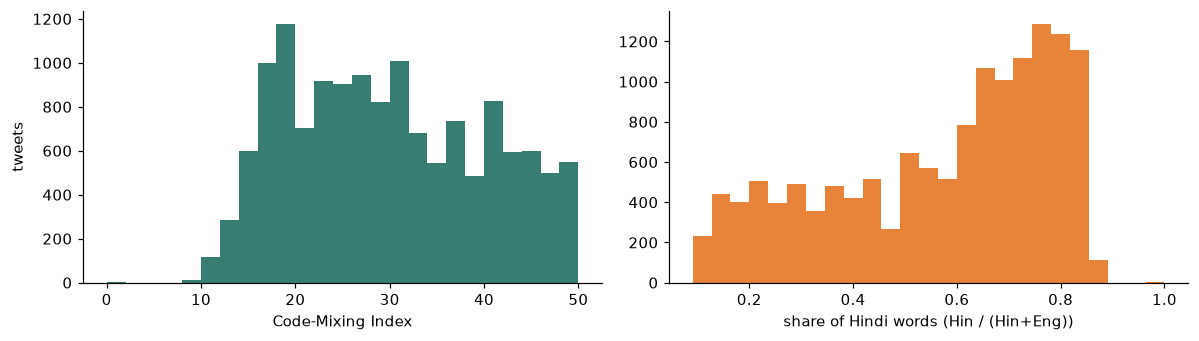

In [9]:
tag_share = pd.Series({t: train[f"n_{t.lower()}"].sum() for t in ["Hin", "Eng", "O", "EMT"]})
print((tag_share / tag_share.sum() * 100).round(1).astype(str) + " %")

mixed = (train.n_hin > 0) & (train.n_eng > 0)
print(f"\nTweets with BOTH Hindi and English words: {mixed.mean()*100:.1f} %")
print(f"Mean CMI: {train.cmi.mean():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(train.cmi, bins=25, color="#377D72"); axes[0].set_xlabel("Code-Mixing Index"); axes[0].set_ylabel("tweets")
hin_ratio = train.n_hin / (train.n_hin + train.n_eng).replace(0, np.nan)
axes[1].hist(hin_ratio.dropna(), bins=25, color="#E8833A"); axes[1].set_xlabel("share of Hindi words (Hin / (Hin+Eng))")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_code_mixing.png"); plt.show()

### 4.4 Spelling variation — the motivation for our **Robust** study

Hindi has no fixed Roman spelling. The same word appears in many forms. We count a few common families in the training set:

In [10]:
from collections import Counter
vocab = Counter(t.lower() for toks, langs in zip(train.tokens, train.langs) for t, l in zip(toks, langs) if l == "Hin")

families = {
    "bahut (very)":   ["bahut", "bohot", "bhot", "bahot", "bht", "bohat", "bhut"],
    "nahi (no)":      ["nahi", "nhi", "nahin", "nai", "ni", "nahee", "nhin"],
    "kya (what)":     ["kya", "kyaa", "kia", "kiya", "kyu", "ky"],
    "hai (is)":       ["hai", "h", "he", "hei", "hain", "hy"],
    "acha (good)":    ["accha", "acha", "achha", "achchha", "achcha", "acchha"],
    "pyaar (love)":   ["pyar", "pyaar", "pyaar", "pyr"],
}
rows = [{"word": fam, "spellings found": ", ".join(f"{v} ({vocab[v]})" for v in dict.fromkeys(vs) if vocab[v] > 0)}
        for fam, vs in families.items()]
pd.DataFrame(rows)

,word,spellings found
0,bahut (very),"bahut (559), bohot (53), bhot (34), bahot (39), bht (30), bohat (37), bhut (95)"
1,nahi (no),"nahi (2528), nhi (706), nahin (73), nai (111), ni (211), nahee (6), nhin (3)"
2,kya (what),"kya (599), kyaa (3), kia (74), kiya (250), kyu (177), ky (28)"
3,hai (is),"hai (4047), h (802), he (508), hei (13), hain (655), hy (66)"
4,acha (good),"accha (28), acha (73), achha (35), achchha (3), achcha (9), acchha (1)"
5,pyaar (love),"pyar (45), pyaar (32)"


In [11]:
print(f"Distinct Hindi word forms in train: {len(vocab):,}")
print(f"Hindi forms seen only once:          {sum(c == 1 for c in vocab.values()):,} "
      f"({sum(c == 1 for c in vocab.values()) / len(vocab) * 100:.0f} %)")
val_vocab = Counter(t.lower() for toks, langs in zip(splits["test"].tokens, splits["test"].langs) for t, l in zip(toks, langs) if l == "Hin")
oov = sum(c for w, c in val_vocab.items() if w not in vocab) / sum(val_vocab.values())
print(f"Test Hindi tokens never seen in train: {oov*100:.1f} %")

Distinct Hindi word forms in train: 26,652
Hindi forms seen only once:          17,184 (64 %)
Test Hindi tokens never seen in train: 10.4 %


### 4.5 Leakage check — identical tweets across splits

In [12]:
tr_text = set(train.text.str.lower())
for name in ["val", "test"]:
    n = splits[name].text.str.lower().isin(tr_text).sum()
    print(f"{name}: {n} tweets ({n/len(splits[name])*100:.2f} %) also appear in train")
print("Small enough to ignore; we keep the official split so results are comparable with SemEval-2020.")

val: 18 tweets (0.60 %) also appear in train
test: 18 tweets (0.60 %) also appear in train
Small enough to ignore; we keep the official split so results are comparable with SemEval-2020.


## 5. Save the fixed split

In [13]:
from hinglish.data import save_splits, load_splits
save_splits(splits, PROC_DIR)
check = load_splits(PROC_DIR)
for n, d in check.items():
    print(f"{n:5s} -> {PROC_DIR / (n + '.jsonl')}  ({len(d):,} rows, columns: {list(d.columns)})")

train -> /Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/data/processed/train.jsonl  (14,000 rows, columns: ['uid', 'text', 'text_raw', 'label', 'label_id', 'tokens', 'langs', 'n_tokens', 'cmi'])
val   -> /Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/data/processed/val.jsonl  (3,000 rows, columns: ['uid', 'text', 'text_raw', 'label', 'label_id', 'tokens', 'langs', 'n_tokens', 'cmi'])
test  -> /Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/data/processed/test.jsonl  (3,000 rows, columns: ['uid', 'text', 'text_raw', 'label', 'label_id', 'tokens', 'langs', 'n_tokens', 'cmi'])


## Summary

- **20,000 real Hinglish tweets**: 14K train / 3K val / 3K test (official SemEval-2020 split), 3 classes, roughly balanced.
- Every word carries a language tag, so for the robustness study we can **respell only the Hindi words**.
- Spelling variation is real and heavy (see 4.4): many Hindi forms appear only once, and a share of test Hindi tokens never appear in training.
- Saved to `data/processed/` → next: `02_baseline_tfidf_calibration.ipynb`.